In [1]:
import os
import random
import subprocess
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import keras
from keras import layers

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

np.random.seed(42)
random.seed(42)
keras.utils.set_random_seed(42)
warnings.filterwarnings("ignore")

print("Keras version:", keras.__version__)

Keras version: 3.13.2


In [2]:
#3. Load data
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
import kagglehub

DATA_DIR = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Dataset path:", DATA_DIR)
print(os.listdir(DATA_DIR))

IMG_SIZE = 32
NUM_CLASSES = 43

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset path: /kaggle/input/gtsrb-german-traffic-sign
['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


In [3]:
def load_img(path):
    with Image.open(path) as img:
        return np.array(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))


def load_train(train_dir):
    paths, labels, groups = [], [], []
    for class_id in range(NUM_CLASSES):
        class_dir = os.path.join(train_dir, str(class_id))
        for file_name in os.listdir(class_dir):
            if not file_name.lower().endswith((".png", ".jpg", ".jpeg", ".ppm")):
                continue
            paths.append(os.path.join(class_dir, file_name))
            labels.append(class_id)
            # file name format: <class>_<track>_<frame>.png -> frames of one track are near-identical
            track_id = file_name.split("_")[1]
            groups.append(f"{class_id}_{track_id}")
    with ThreadPoolExecutor(max_workers=16) as ex:
        images = list(tqdm(ex.map(load_img, paths), total=len(paths), desc="Train"))
    return np.array(images), np.array(labels), np.array(groups)


def load_test(data_dir):
    df = pd.read_csv(os.path.join(data_dir, "Test.csv"))
    paths = [os.path.join(data_dir, p) for p in df["Path"]]
    with ThreadPoolExecutor(max_workers=16) as ex:
        images = list(tqdm(ex.map(load_img, paths), total=len(paths), desc="Test"))
    return np.array(images), df["ClassId"].values


CACHE = "/content/gtsrb_data.npz" if os.path.exists("/content") else "gtsrb_data.npz"

if os.path.exists(CACHE):
    d = np.load(CACHE, allow_pickle=True)
    X_train_raw, y_train_all, groups = d["X_train"], d["y_train"], d["groups"]
    X_test_raw, y_test = d["X_test"], d["y_test"]
    print("Loaded from cache:", CACHE)
else:
    X_train_raw, y_train_all, groups = load_train(os.path.join(DATA_DIR, "Train"))
    X_test_raw, y_test = load_test(DATA_DIR)
    np.savez_compressed(
        CACHE,
        X_train=X_train_raw, y_train=y_train_all, groups=groups,
        X_test=X_test_raw, y_test=y_test,
    )
    print("Saved cache:", CACHE)

print("X_train_raw shape:", X_train_raw.shape)
print("y_train_all shape:", y_train_all.shape)
print("X_test_raw shape:", X_test_raw.shape)
print("y_test shape:", y_test.shape)
print("Number of tracks:", len(np.unique(groups)))

Test: 100%|██████████| 12630/12630 [00:09<00:00, 1267.78it/s]


Saved cache: /content/gtsrb_data.npz
X_train_raw shape: (39209, 32, 32, 3)
y_train_all shape: (39209,)
X_test_raw shape: (12630, 32, 32, 3)
y_test shape: (12630,)
Number of tracks: 1307


In [4]:
class_names = [
    "Speed limit (20km/h)", "Speed limit (30km/h)", "Speed limit (50km/h)", "Speed limit (60km/h)",
    "Speed limit (70km/h)", "Speed limit (80km/h)", "End of speed limit (80km/h)", "Speed limit (100km/h)",
    "Speed limit (120km/h)", "No passing", "No passing for vehicles over 3.5 tons",
    "Right-of-way at next intersection", "Priority road", "Yield", "Stop", "No vehicles",
    "Vehicles over 3.5 tons prohibited", "No entry", "General caution", "Dangerous curve to the left",
    "Dangerous curve to the right", "Double curve", "Bumpy road", "Slippery road",
    "Road narrows on the right", "Road work", "Traffic signals", "Pedestrians", "Children crossing",
    "Bicycles crossing", "Beware of ice/snow", "Wild animals crossing", "End of all speed and passing limits",
    "Turn right ahead", "Turn left ahead", "Ahead only", "Go straight or right", "Go straight or left",
    "Keep right", "Keep left", "Roundabout mandatory", "End of no passing",
    "End of no passing by vehicles over 3.5 tons",
]

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

0: Speed limit (20km/h)
1: Speed limit (30km/h)
2: Speed limit (50km/h)
3: Speed limit (60km/h)
4: Speed limit (70km/h)
5: Speed limit (80km/h)
6: End of speed limit (80km/h)
7: Speed limit (100km/h)
8: Speed limit (120km/h)
9: No passing
10: No passing for vehicles over 3.5 tons
11: Right-of-way at next intersection
12: Priority road
13: Yield
14: Stop
15: No vehicles
16: Vehicles over 3.5 tons prohibited
17: No entry
18: General caution
19: Dangerous curve to the left
20: Dangerous curve to the right
21: Double curve
22: Bumpy road
23: Slippery road
24: Road narrows on the right
25: Road work
26: Traffic signals
27: Pedestrians
28: Children crossing
29: Bicycles crossing
30: Beware of ice/snow
31: Wild animals crossing
32: End of all speed and passing limits
33: Turn right ahead
34: Turn left ahead
35: Ahead only
36: Go straight or right
37: Go straight or left
38: Keep right
39: Keep left
40: Roundabout mandatory
41: End of no passing
42: End of no passing by vehicles over 3.5 tons


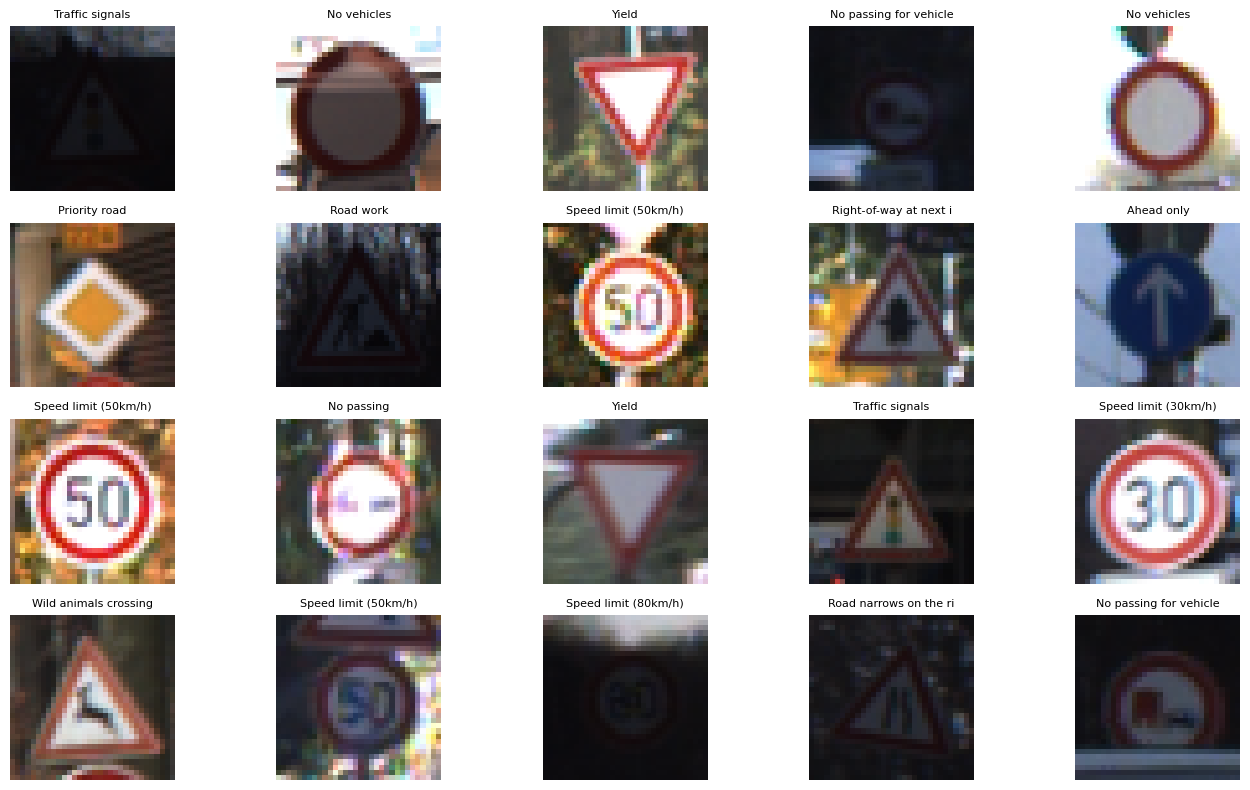

In [5]:
#5. EDA: sample img
plt.figure(figsize=(14, 8))
random_idx = np.random.choice(len(X_train_raw), 20, replace=False)
for plot_no, idx in enumerate(random_idx):
    plt.subplot(4, 5, plot_no + 1)
    plt.imshow(X_train_raw[idx])
    plt.title(class_names[y_train_all[idx]][:22], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

,Label,Class,Count
0,0,Speed limit (20km/h),210
1,1,Speed limit (30km/h),2220
2,2,Speed limit (50km/h),2250
3,3,Speed limit (60km/h),1410
4,4,Speed limit (70km/h),1980
5,5,Speed limit (80km/h),1860
6,6,End of speed limit (80km/h),420
7,7,Speed limit (100km/h),1440
8,8,Speed limit (120km/h),1410
9,9,No passing,1470


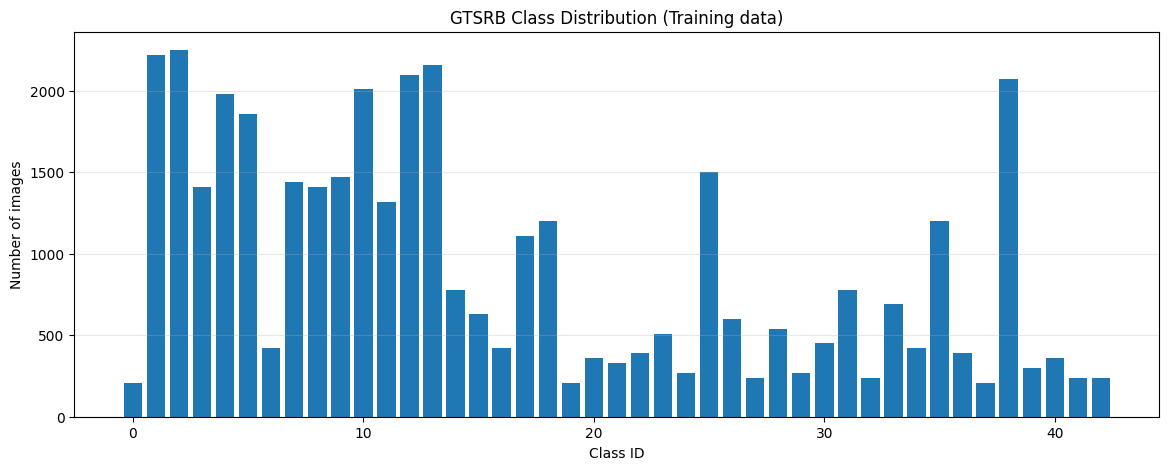

In [6]:
# Classs distibution - EDA
unique_labels, counts = np.unique(y_train_all, return_counts=True)
class_distribution = pd.DataFrame({
    "Label": unique_labels,
    "Class": [class_names[i] for i in unique_labels],
    "Count": counts,
})
display(class_distribution)

plt.figure(figsize=(14, 5))
plt.bar(class_distribution["Label"], class_distribution["Count"])
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.title("GTSRB Class Distribution (Training data)")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [7]:
sample_idx = np.random.choice(len(X_train_raw), 2000, replace=False)
duplicate_check = X_train_raw[sample_idx].reshape(2000, -1)

unique_rows = np.unique(duplicate_check, axis=0)

print("Images checked:", len(duplicate_check))
print("Unique rows:", len(unique_rows))
print("Duplicates in this sample:", len(duplicate_check) - len(unique_rows))

Images checked: 2000
Unique rows: 2000
Duplicates in this sample: 0


In [8]:
# 8. Normalisation
x_train_all = X_train_raw.astype("float32") / 255.0
x_test = X_test_raw.astype("float32") / 255.0

print("Data type:", x_train_all.dtype)
print("Minimum pixel value:", x_train_all.min())
print("Maximum pixel value:", x_train_all.max())
print("NaN values in train:", np.isnan(x_train_all).sum())
print("NaN values in test:", np.isnan(x_test).sum())
print("Infinite values in train:", np.isinf(x_train_all).sum())
print("Infinite values in test:", np.isinf(x_test).sum())

Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
NaN values in train: 0
NaN values in test: 0
Infinite values in train: 0
Infinite values in test: 0


In [9]:
#9. Track-wise train/validation split (no leakage between frames of one sign)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, val_idx = next(gss.split(x_train_all, y_train_all, groups))

x_train, y_train = x_train_all[train_idx], y_train_all[train_idx]
x_val, y_val = x_train_all[val_idx], y_train_all[val_idx]

assert len(set(groups[train_idx]) & set(groups[val_idx])) == 0, "Track leakage!"

print("Training  :", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test      :", x_test.shape, y_test.shape)
print("Classes in val:", len(np.unique(y_val)), "/", NUM_CLASSES)

Training  : (31349, 32, 32, 3) (31349,)
Validation: (7860, 32, 32, 3) (7860,)
Test      : (12630, 32, 32, 3) (12630,)
Classes in val: 41 / 43


In [10]:
#  10. ANN baseline
ann_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="ann")

ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
ann_model.summary()

Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 825,131 (3.15 MB)

 Trainable params: 825,131 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#11. Train ANN
history_ann = ann_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1,
)

Epoch 1/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.3548 - loss: 2.3707 - val_accuracy: 0.5673 - val_loss: 1.5530
Epoch 2/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.6182 - loss: 1.2710 - val_accuracy: 0.7104 - val_loss: 1.0271
Epoch 3/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7060 - loss: 0.9734 - val_accuracy: 0.7720 - val_loss: 0.7825
Epoch 4/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.7482 - loss: 0.8307 - val_accuracy: 0.8111 - val_loss: 0.7359
Epoch 5/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.7764 - loss: 0.7376 - val_accuracy: 0.8328 - val_loss: 0.6410
Epoch 6/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.7983 - loss: 0.6661 - val_accuracy: 0.8352 - val_loss: 0.5977
Epoch 7/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.8113 - loss: 0.6183 - val_accuracy: 0.8385 - val_loss: 0.5885
Epoch 8/10
490/490 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8151 - loss: 0.6115 - val_a

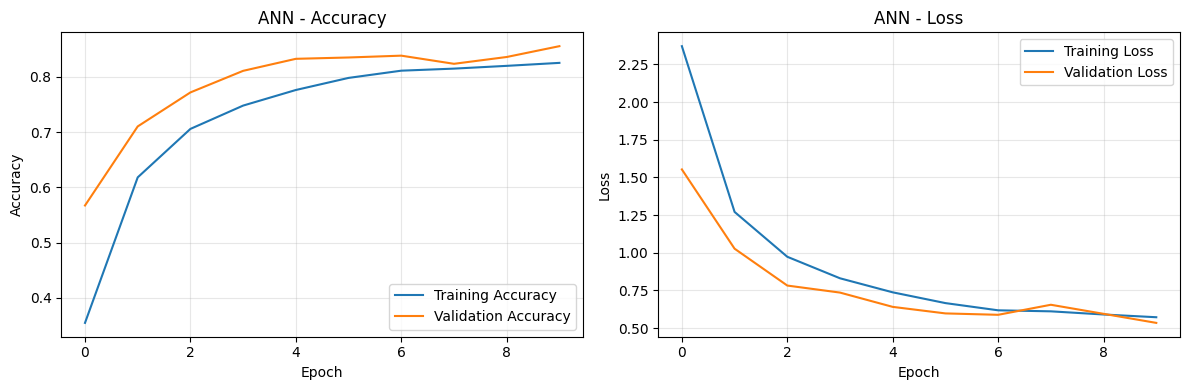

In [12]:
# 12. ANN curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history["accuracy"], label="Training Accuracy")
plt.plot(history_ann.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("ANN - Accuracy")
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_ann.history["loss"], label="Training Loss")
plt.plot(history_ann.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("ANN - Loss")
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

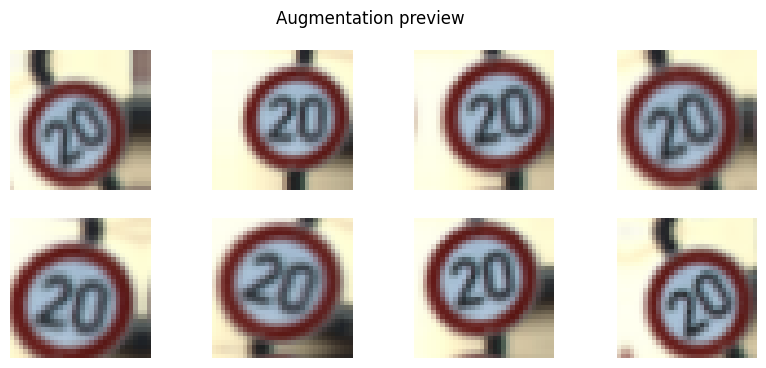

In [13]:
#13. Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
], name="data_augmentation")


# Preview augmentation
plt.figure(figsize=(10, 4))
sample = x_train[:1]
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(data_augmentation(sample, training=True)[0])
    plt.axis("off")
plt.suptitle("Augmentation preview")
plt.show()


In [14]:
#14. CNN (augmentation is now part of the model, active only during training)
cnn_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),  # fixed: was Dense
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="cnn")
cnn_model.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,963 (1.38 MB)

 Trainable params: 361,515 (1.38 MB)

 Non-trainable params: 448 (1.75 KB)

In [15]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [20]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
]

In [21]:
history_cnn = cnn_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks = callbacks,
    verbose=1,
)

Epoch 1/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 121s 239ms/step - accuracy: 0.4038 - loss: 2.0730 - val_accuracy: 0.5298 - val_loss: 1.4881
Epoch 2/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 136s 228ms/step - accuracy: 0.7171 - loss: 0.8629 - val_accuracy: 0.7639 - val_loss: 0.7620
Epoch 3/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 147s 237ms/step - accuracy: 0.8510 - loss: 0.4514 - val_accuracy: 0.8522 - val_loss: 0.4358
Epoch 4/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 139s 232ms/step - accuracy: 0.9009 - loss: 0.3025 - val_accuracy: 0.9243 - val_loss: 0.2276
Epoch 5/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 139s 226ms/step - accuracy: 0.9296 - loss: 0.2225 - val_accuracy: 0.9341 - val_loss: 0.2089
Epoch 6/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 111s 228ms/step - accuracy: 0.9411 - loss: 0.1814 - val_accuracy: 0.9145 - val_loss: 0.2724
Epoch 7/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 141s 227ms/step - accuracy: 0.9530 - loss: 0.1466 - val_accuracy: 0.9355 - val_loss: 0.2205
Epoch 8/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 145s 234ms/step - accuracy: 0.9560 -

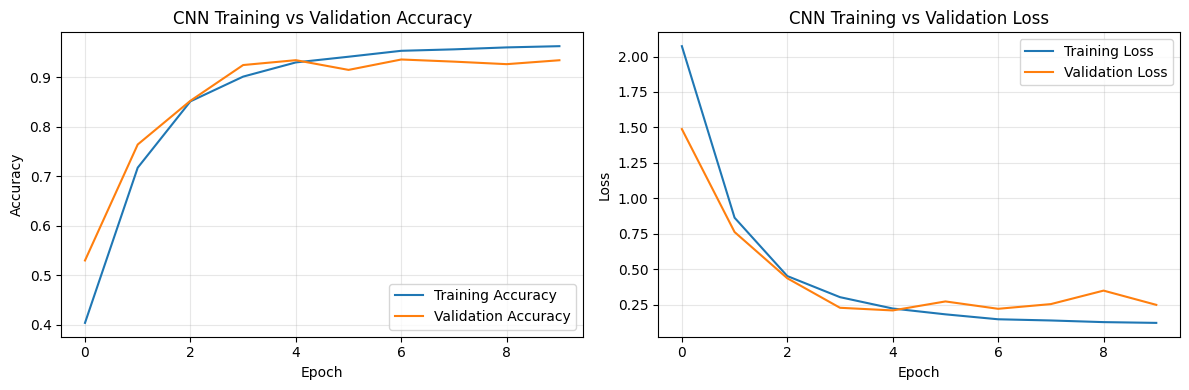

In [22]:
#16. CNN curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("CNN Training vs Validation Accuracy")
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("CNN Training vs Validation Loss")
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
#17. Final evaluation on the held-out TEST set (report these numbers)
ann_probs = ann_model.predict(x_test, verbose=0)
cnn_probs = cnn_model.predict(x_test, verbose=0)

y_pred_ann = np.argmax(ann_probs, axis=1)
y_pred_cnn = np.argmax(cnn_probs, axis=1)

acc_ann = accuracy_score(y_test, y_pred_ann)
acc_cnn = accuracy_score(y_test, y_pred_cnn)

val_acc_cnn = cnn_model.evaluate(x_val, y_val, verbose=0)[1]

print("ANN test accuracy:", round(acc_ann, 4))
print("CNN validation accuracy:", round(val_acc_cnn, 4))
print("CNN test accuracy:", round(acc_cnn, 4))

ANN test accuracy: 0.8216
CNN validation accuracy: 0.9341
CNN test accuracy: 0.9233


In [25]:
#18. Classification report
print(classification_report(
    y_test, y_pred_cnn,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
))


                                             precision    recall  f1-score   support

                       Speed limit (20km/h)       0.75      0.95      0.84        60
                       Speed limit (30km/h)       0.93      0.96      0.94       720
                       Speed limit (50km/h)       0.87      0.92      0.89       750
                       Speed limit (60km/h)       0.94      0.76      0.84       450
                       Speed limit (70km/h)       0.94      0.97      0.96       660
                       Speed limit (80km/h)       0.81      0.81      0.81       630
                End of speed limit (80km/h)       0.93      0.97      0.95       150
                      Speed limit (100km/h)       0.98      0.85      0.91       450
                      Speed limit (120km/h)       0.84      0.94      0.88       450
                                 No passing       0.96      1.00      0.98       480
      No passing for vehicles over 3.5 tons       1.00      0.97

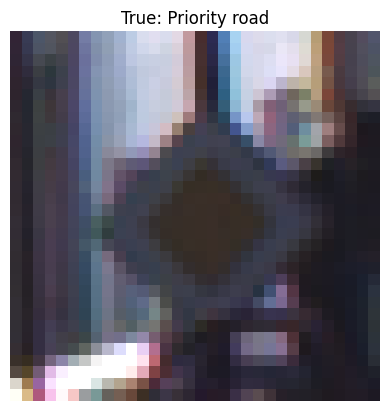

Top 3 Predictions:

End of no passing by vehicles over 3.5 tons -> 85.28 %
End of speed limit (80km/h) -> 4.35 %
Keep right -> 3.61 %


In [26]:
#19. Top-3 predictions for one test image
sample_index = 10
probabilities = cnn_probs[sample_index]
top3_indices = np.argsort(probabilities)[-3:][::-1]

plt.imshow(x_test[sample_index])
plt.axis("off")
plt.title("True: " + class_names[y_test[sample_index]])
plt.show()

print("Top 3 Predictions:\n")
for idx in top3_indices:
    print(f"{class_names[idx]} -> {probabilities[idx] * 100:.2f} %")

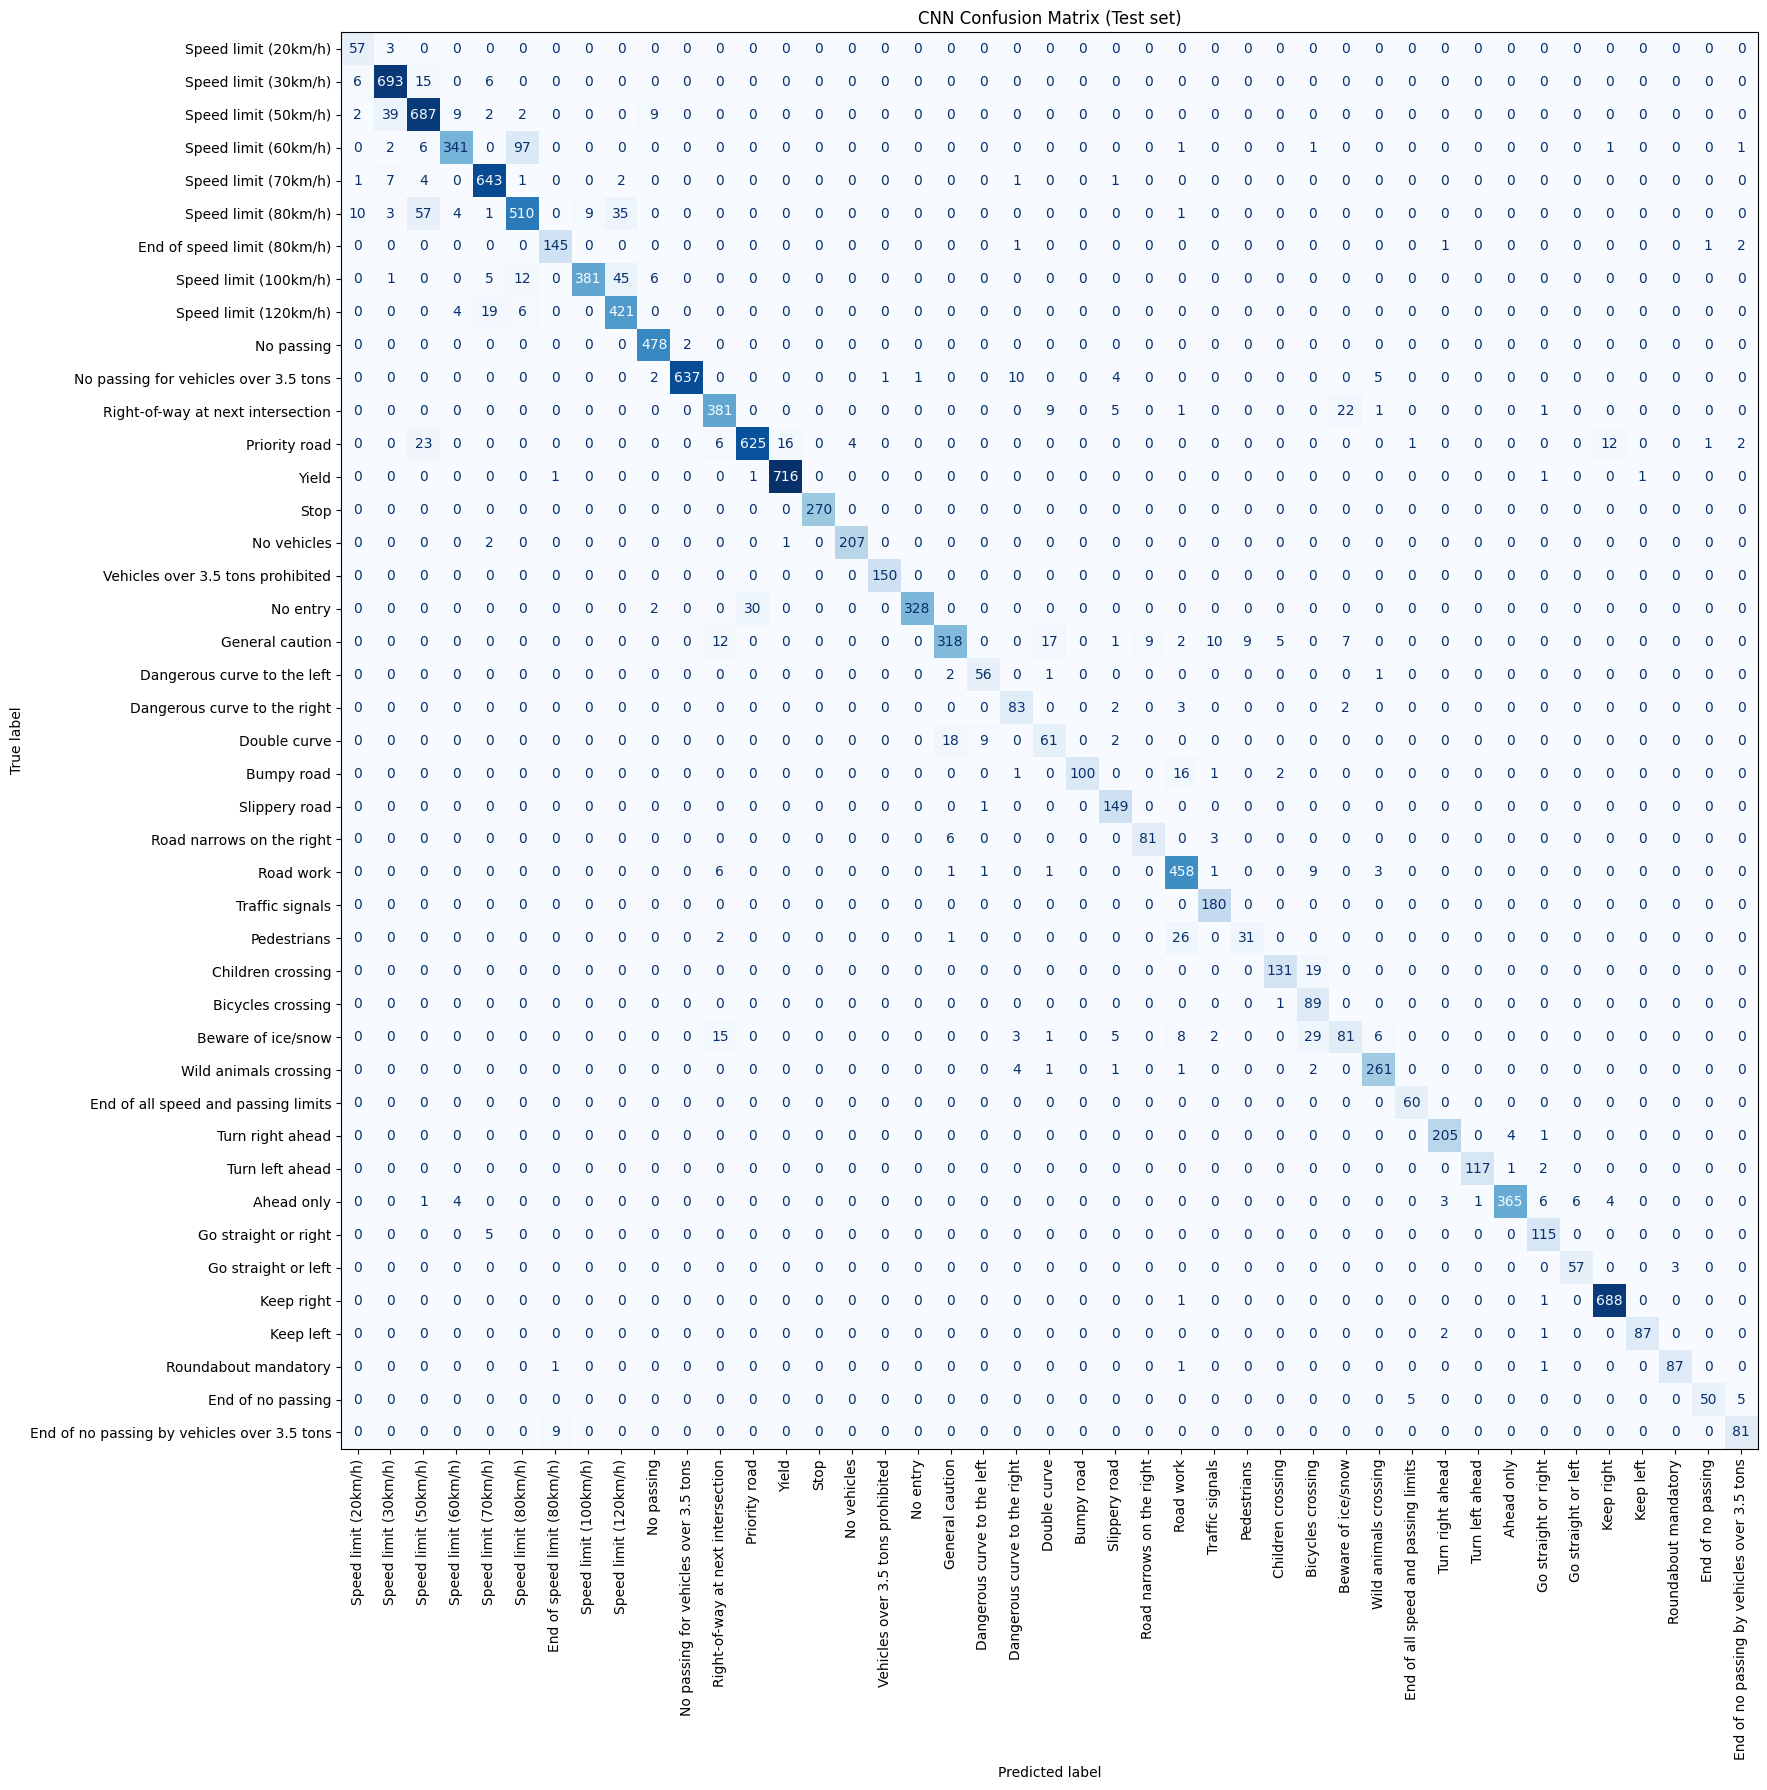

In [27]:
#20. Confusion matrix (counts)
cm = confusion_matrix(y_test, y_pred_cnn, labels=list(range(NUM_CLASSES)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(18, 18))
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("CNN Confusion Matrix (Test set)")
plt.tight_layout()
plt.show()

In [30]:
#22. Per-class accuracy: weakest classes
per_class_acc = cm.diagonal() / cm.sum(axis=1)
weak = pd.DataFrame({
    "Class": class_names,
    "Test images": cm.sum(axis=1),
    "Accuracy": per_class_acc.round(4),
}).sort_values("Accuracy").head(10)
display(weak)

,Class,Test images,Accuracy
27,Pedestrians,60,0.5167
30,Beware of ice/snow,150,0.5400
21,Double curve,90,0.6778
3,Speed limit (60km/h),450,0.7578
5,Speed limit (80km/h),630,0.8095
18,General caution,390,0.8154
22,Bumpy road,120,0.8333
41,End of no passing,60,0.8333
7,Speed limit (100km/h),450,0.8467
28,Children crossing,150,0.8733


Wrong predictions: 969 out of 12630


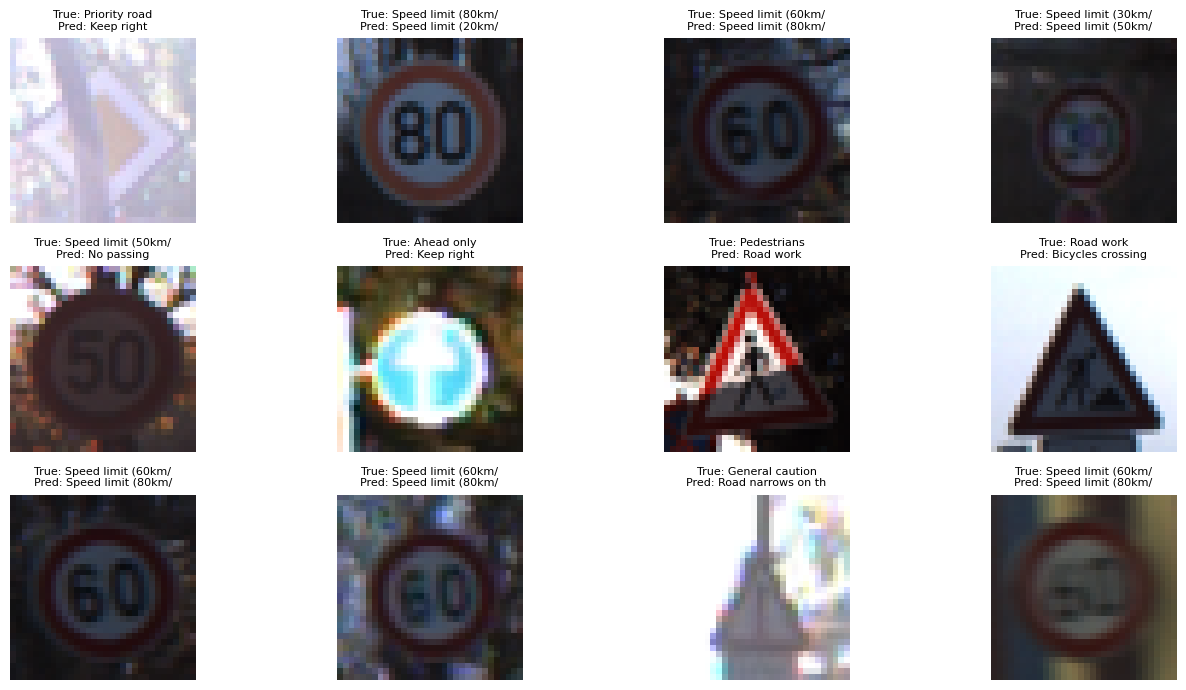

In [31]:
#23. Wrong predictions
wrong_idx = np.where(y_pred_cnn != y_test)[0]
print("Wrong predictions:", len(wrong_idx), "out of", len(y_test))

if len(wrong_idx) > 0:
    show_idx = np.random.choice(wrong_idx, min(12, len(wrong_idx)), replace=False)
    plt.figure(figsize=(14, 7))
    for plot_no, idx in enumerate(show_idx):
        plt.subplot(3, 4, plot_no + 1)
        plt.imshow(x_test[idx])
        plt.title(
            f"True: {class_names[y_test[idx]][:18]}\nPred: {class_names[y_pred_cnn[idx]][:18]}",
            fontsize=8,
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()

,Model,Test Accuracy
0,ANN,0.8216
1,CNN,0.9233


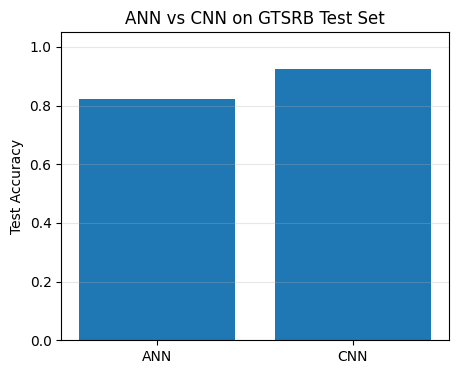

In [32]:
#24. ANN vs CNN comparison
comparison_df = pd.DataFrame({
    "Model": ["ANN", "CNN"],
    "Test Accuracy": [round(acc_ann, 4), round(acc_cnn, 4)],
})
display(comparison_df)

plt.figure(figsize=(5, 4))
plt.bar(comparison_df["Model"], comparison_df["Test Accuracy"])
plt.ylabel("Test Accuracy")
plt.title("ANN vs CNN on GTSRB Test Set")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [33]:
#25. Save final model
cnn_model.save("gtsrb_cnn.keras")
print("Model saved: gtsrb_cnn.keras")

Model saved: gtsrb_cnn.keras
